# Olist E-commerce Analysis
## What drives revenue, and do late deliveries hurt customer reviews?

**Dataset:** [Olist Brazilian E-Commerce (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), about 100K orders, Sep 2016 to Oct 2018
**Tools:** Python, pandas, matplotlib, seaborn, scipy

**How to run:** set `folder` in Step 1 to the folder with the CSV files, then run the cells top to bottom.

## Step 1: Load the data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme()
os.makedirs('charts', exist_ok=True)   # charts are saved here for your README

folder = "D:/"   # change this if your CSV files are somewhere else. Type it by hand, do not paste.

cust   = pd.read_csv(folder + "olist_customers_dataset.csv")
items  = pd.read_csv(folder + "olist_order_items_dataset.csv")
rev    = pd.read_csv(folder + "olist_order_reviews_dataset.csv")
orders = pd.read_csv(folder + "olist_orders_dataset.csv")
prod   = pd.read_csv(folder + "olist_products_dataset.csv")
trans  = pd.read_csv(folder + "product_category_name_translation.csv")

for name, d in [('cust', cust), ('items', items), ('rev', rev),
                ('orders', orders), ('prod', prod), ('trans', trans)]:
    print(name, d.shape)

cust (99441, 5)
items (112650, 7)
rev (99224, 7)
orders (99441, 8)
prod (32951, 9)
trans (71, 2)


## Step 2: Check the data quality

In [2]:
# Missing values in orders
nulls = orders.isnull().sum()
print(nulls[nulls > 0])

# Orders by status
print(orders['order_status'].value_counts())

# Are the dates real dates yet?
print(orders['order_purchase_timestamp'].dtype)

# Duplicates
print('Duplicate orders:', orders['order_id'].duplicated().sum())
print('Duplicate customers:', cust['customer_id'].duplicated().sum())
print('Duplicate item rows:', items.duplicated(['order_id', 'order_item_id']).sum())
print('Orders with 2+ reviews:', rev['order_id'].duplicated().sum())

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
str
Duplicate orders: 0
Duplicate customers: 0
Duplicate item rows: 0
Orders with 2+ reviews: 551


**Insight:** 2,965 orders have no delivery date because they never reached the customer. Most are shipped (1,107), canceled (619), unavailable (609), invoiced (314) or processing (301). With no delivery date there is nothing to compare against the estimated date, so delay cannot be measured. Filling in a made-up date would distort every delivery result, so these orders are removed in Step 4.

## Step 3: Convert the dates

In [3]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

print(orders[['order_purchase_timestamp', 'order_delivered_customer_date',
              'order_estimated_delivery_date']].dtypes)

order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


## Step 4: Keep delivered orders

In [4]:
delivered = orders[orders['order_status'] == 'delivered']
delivered = delivered.dropna(subset=['order_delivered_customer_date'])
print(f"Orders: {len(orders):,} -> {len(delivered):,} (removed {len(orders) - len(delivered):,})")

Orders: 99,441 -> 96,470 (removed 2,971)


## Step 5: Create the delivery columns

In [5]:
delivered['delivery_days'] = (delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']).dt.days
delivered['delay_days'] = (delivered['order_delivered_customer_date'] - delivered['order_estimated_delivery_date']).dt.days
delivered['is_late'] = delivered['delay_days'] > 0   # delivered after the promised date

print('Late rate %:', round(delivered['is_late'].mean() * 100, 2))
print('Median delivery days:', delivered['delivery_days'].median())
print('Negative delivery days:', (delivered['delivery_days'] < 0).sum())

Late rate %: 6.77
Median delivery days: 10.0
Negative delivery days: 0


## Step 6: Combine the tables into one

In [6]:
# One review score per order (average if there are several)
rev_score = rev.groupby('order_id', as_index=False)['review_score'].mean()

# English category names; missing ones become 'unknown'
prod = prod.merge(trans, on='product_category_name', how='left')
prod['category'] = prod['product_category_name_english'].fillna('unknown')
print('Unknown categories:', (prod['category'] == 'unknown').sum())

# Item level table: one row per item sold (use for revenue)
df = (items.merge(delivered[['order_id', 'customer_id', 'order_purchase_timestamp',
                             'delivery_days', 'delay_days', 'is_late']], on='order_id')
           .merge(prod[['product_id', 'category']], on='product_id', how='left')
           .merge(cust[['customer_id', 'customer_state']], on='customer_id', how='left')
           .merge(rev_score, on='order_id', how='left'))

# Order level table: one row per order (use for delivery and review analysis)
o = (delivered.merge(rev_score, on='order_id', how='left')
              .merge(cust[['customer_id', 'customer_state']], on='customer_id', how='left'))

print('Item table:', df.shape, '| Order table:', o.shape)
print('Total revenue:', round(df['price'].sum(), 2))
print('Items with no review score:', df['review_score'].isnull().sum())

Unknown categories: 623
Item table: (110189, 15) | Order table: (96470, 13)
Total revenue: 13220248.93
Items with no review score: 827


**Insight:** the item table has one row per item sold, so an order with 3 items appears 3 times. That is right for revenue, but wrong for delivery and reviews, because one order has one delivery and one review. Counting late orders from the item table would count big orders several times and overstate their weight. So revenue uses the item table, and delivery and review analysis use the order table.

## Step 7: Revenue analysis

Top 5 share %: 39.8
Top 10 share %: 62.4


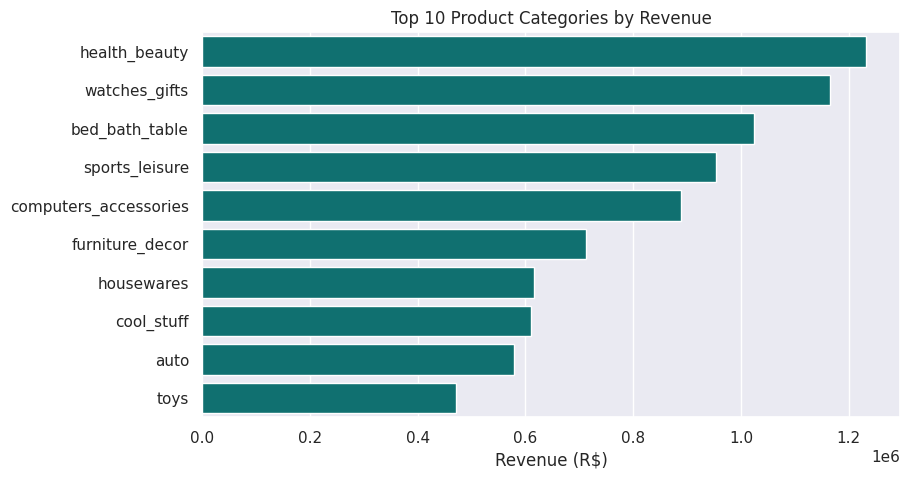

In [7]:
# 7a. Top 10 categories by revenue
cat_rev = df.groupby('category')['price'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=cat_rev.values, y=cat_rev.index, color='teal')
plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('')
plt.savefig('charts/01_top_categories.png', dpi=150, bbox_inches='tight')
plt.show()

total = df['price'].sum()
print('Top 5 share %:', round(cat_rev.head(5).sum() / total * 100, 1))
print('Top 10 share %:', round(cat_rev.sum() / total * 100, 1))

customer_state
SP    38.3
RJ    13.3
MG    11.7
RS     5.5
PR     5.0
SC     3.8
BA     3.7
DF     2.2
GO     2.1
ES     2.0
Name: price, dtype: float64


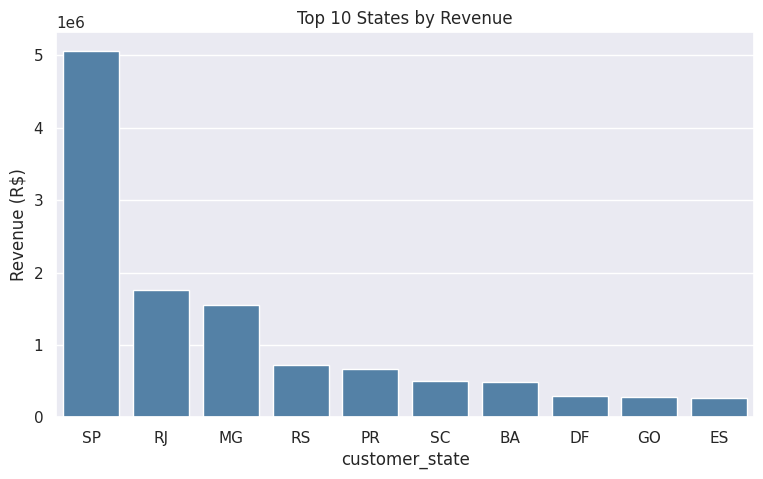

In [8]:
# 7b. Top 10 states by revenue
state_rev = df.groupby('customer_state')['price'].sum().sort_values(ascending=False).head(10)
print((state_rev / total * 100).round(1))

plt.figure(figsize=(9, 5))
sns.barplot(x=state_rev.index, y=state_rev.values, color='steelblue')
plt.title('Top 10 States by Revenue')
plt.ylabel('Revenue (R$)')
plt.savefig('charts/02_top_states.png', dpi=150, bbox_inches='tight')
plt.show()

Peak month: 2017-11 987648


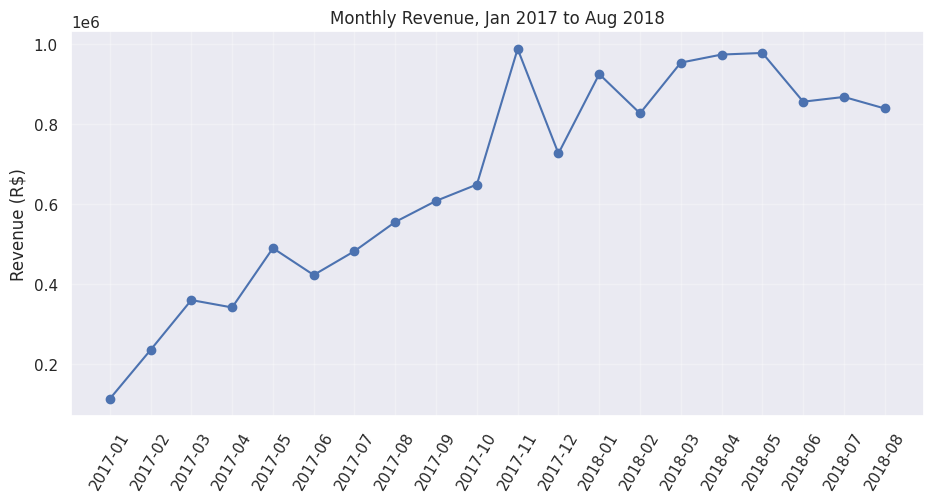

In [9]:
# 7c. Monthly revenue trend (2016 and late 2018 are incomplete, so use Jan 2017 to Aug 2018)
df['month'] = df['order_purchase_timestamp'].dt.to_period('M')
monthly = df.groupby('month')['price'].sum()['2017-01':'2018-08']

plt.figure(figsize=(11, 5))
plt.plot(monthly.index.astype(str), monthly.values, marker='o')
plt.xticks(rotation=60)
plt.title('Monthly Revenue, Jan 2017 to Aug 2018')
plt.ylabel('Revenue (R$)')
plt.grid(alpha=0.3)
plt.savefig('charts/03_monthly_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peak month:', monthly.idxmax(), round(monthly.max()))

**Insights:**
1. Revenue is concentrated. The top 5 categories make up 39.8% of revenue and the top 10 make up 62.4%. Sao Paulo (SP) alone generates 38.3%, followed by RJ (13.3%) and MG (11.7%).
2. Revenue grew strongly from about R$ 112K in January 2017 to a peak of about R$ 988K in November 2017. The November spike is consistent with holiday and Black Friday shopping, but this data alone does not prove the reason.

## Step 8: Delivery performance

Late delivery rate: 6.77%
Median delivery time: 10.0 days
                orders  late_rate
customer_state                   
MA                 717       17.4
CE                1279       13.8
BA                3256       12.2


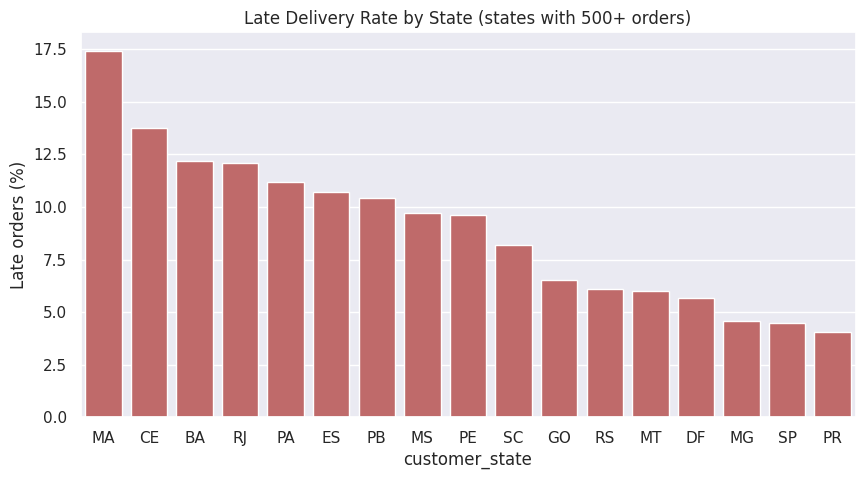

In [10]:
print(f"Late delivery rate: {o['is_late'].mean() * 100:.2f}%")
print(f"Median delivery time: {o['delivery_days'].median()} days")

# Late rate by state (only states with 500+ orders)
state_stats = o.groupby('customer_state').agg(orders=('order_id', 'count'),
                                              late_rate=('is_late', 'mean'))
state_stats = state_stats[state_stats['orders'] >= 500].sort_values('late_rate', ascending=False)
state_stats['late_rate'] = state_stats['late_rate'] * 100
print(state_stats.head(3).round(1))

plt.figure(figsize=(10, 5))
sns.barplot(x=state_stats.index, y=state_stats['late_rate'], color='indianred')
plt.title('Late Delivery Rate by State (states with 500+ orders)')
plt.ylabel('Late orders (%)')
plt.savefig('charts/04_late_rate_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight:** among states with 500+ orders, the worst late rates are MA (17.4%), CE (13.8%) and BA (12.2%), compared with 4.5% in SP. RJ (12.1%) is also high even though it is in the southeast, so distance alone does not explain the pattern. The causes were not tested in this analysis.

## Step 9: Do late deliveries hurt reviews?

         mean  count
is_late             
False    4.29  89443
True     2.27   6381


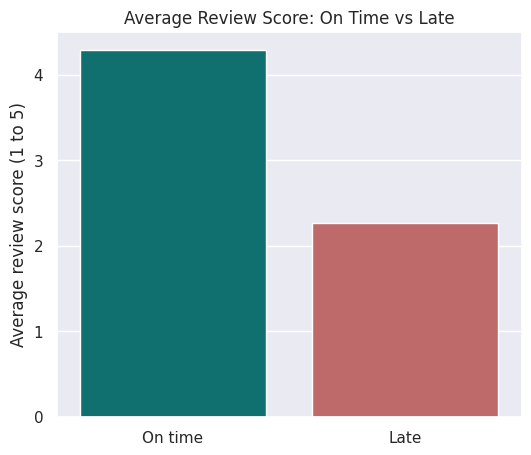

In [11]:
print(o.groupby('is_late')['review_score'].agg(['mean', 'count']).round(2))

plt.figure(figsize=(6, 5))
sns.barplot(data=o, x='is_late', y='review_score', hue='is_late', errorbar=None,
            palette=['teal', 'indianred'], legend=False)
plt.xticks([0, 1], ['On time', 'Late'])
plt.title('Average Review Score: On Time vs Late')
plt.xlabel('')
plt.ylabel('Average review score (1 to 5)')
plt.savefig('charts/05_review_late_vs_ontime.png', dpi=150, bbox_inches='tight')
plt.show()

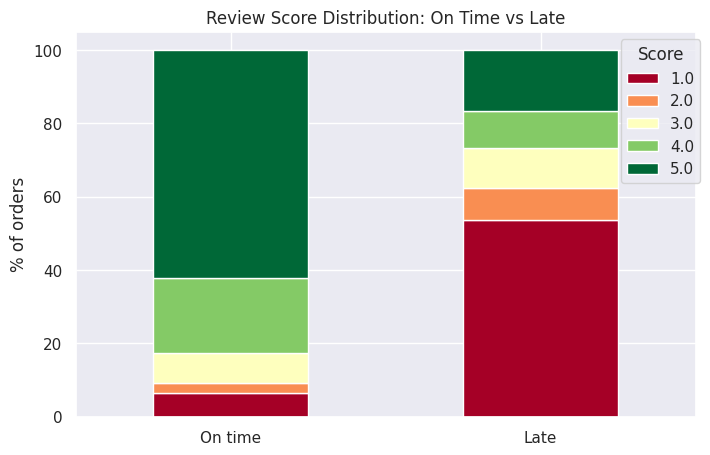

In [12]:
# Share of each score, on time vs late
dist = pd.crosstab(o['is_late'], o['review_score'].round(), normalize='index') * 100
dist.index = ['On time', 'Late']
dist.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='RdYlGn')
plt.title('Review Score Distribution: On Time vs Late')
plt.ylabel('% of orders')
plt.xticks(rotation=0)
plt.legend(title='Score', bbox_to_anchor=(1.02, 1))
plt.savefig('charts/06_score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 10: Is the difference real? (statistical test)

In [13]:
# Review scores are ordinal (1 to 5), so use Mann-Whitney U instead of a t-test
late   = o.loc[o['is_late'],  'review_score'].dropna()
ontime = o.loc[~o['is_late'], 'review_score'].dropna()

u_stat, p_value = stats.mannwhitneyu(late, ontime)
print('p-value:', 'p < 0.001' if p_value < 0.001 else round(p_value, 4))
print(f'Mean review: late = {late.mean():.2f}, on time = {ontime.mean():.2f}')

p-value: p < 0.001
Mean review: late = 2.27, on time = 4.29


**Insights:**
1. Late orders average 2.27 stars against 4.29 for on-time orders, and 53.7% of late orders get a 1-star review against 6.6% of on-time orders. The p-value is below 0.001, which means a gap this large would almost never appear by chance if late delivery had no effect on reviews.
2. Review scores are ordinal (1 to 5), so Mann-Whitney U is a safer choice than a t-test. It compares the rankings of the two groups and does not assume the scores are normally distributed.
3. This shows an association, not proof of cause. Product quality, a wrong or damaged item, or customer expectations could also affect both lateness and the score.

## Step 11: Business recommendations

1. **Fix delivery reliability in the worst states first.** MA, CE and BA have late rates of 12% to 17%, against 4.5% in SP. Review carrier performance and delivery-date estimates there.
2. **Treat late delivery as the main review risk.** Late orders are only 6.8% of volume, but 53.7% of them get 1-star reviews. Warn customers early when an order is at risk of being late.
3. **Protect the revenue base.** SP and the top 5 categories carry a large share of revenue, and sales peak in November. Plan stock and logistics capacity ahead of the November peak.

## Limitations
- Only delivered orders are included (2,971 orders removed)
- Revenue is item price and excludes freight
- "Late" is measured against Olist's own estimated delivery date
- 827 items have no review score and were left as missing
- This shows an association between late delivery and low scores, not proof of cause

## Tools
Python, pandas, matplotlib, seaborn, scipy